# DATA 620 — Week 6 Women Network Analysis

In [1]:

import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
from networkx.algorithms import bipartite

# ==================================================




## Introduction

This assignment examines the Davis Southern Women dataset using Python and NetworkX. The dataset contains 18 women and 14 social events, with 89 attendance relationships. The main goal is to understand what shared event participation can tell us about relationships among the women and among the events.

I examine two questions: Which women appear to participate in similar social circles, and which events attract overlapping groups of attendees?

## 1. Dataset and Network Structure

The original data is a **bipartite network**, meaning that its two sets of nodes are women and events. An edge means that a woman attended an event. I first check the size and structure of the dataset so I know what relationships the network actually represents.

In [1]:
# 1. LOAD THE DAVIS SOUTHERN WOMEN DATASET
# ==================================================

G = nx.davis_southern_women_graph()

women = list(G.graph["top"])
events = list(G.graph["bottom"])

print("ORIGINAL NETWORK")
print("--------------------------------")
print("Number of women:", len(women))
print("Number of events:", len(events))
print("Total nodes:", G.number_of_nodes())
print("Total attendance connections:", G.number_of_edges())
print("Bipartite network:", bipartite.is_bipartite(G))


# ==================================================


ORIGINAL NETWORK
--------------------------------
Number of women: 18
Number of events: 14
Total nodes: 32
Total attendance connections: 89
Bipartite network: True


## 2. Original Bipartite Network

I first visualize the original network without transforming the data. Separating women and events into two columns makes the meaning of each edge clear and shows how attendance connects the two groups. Because there are 89 edges, some overlap is expected.

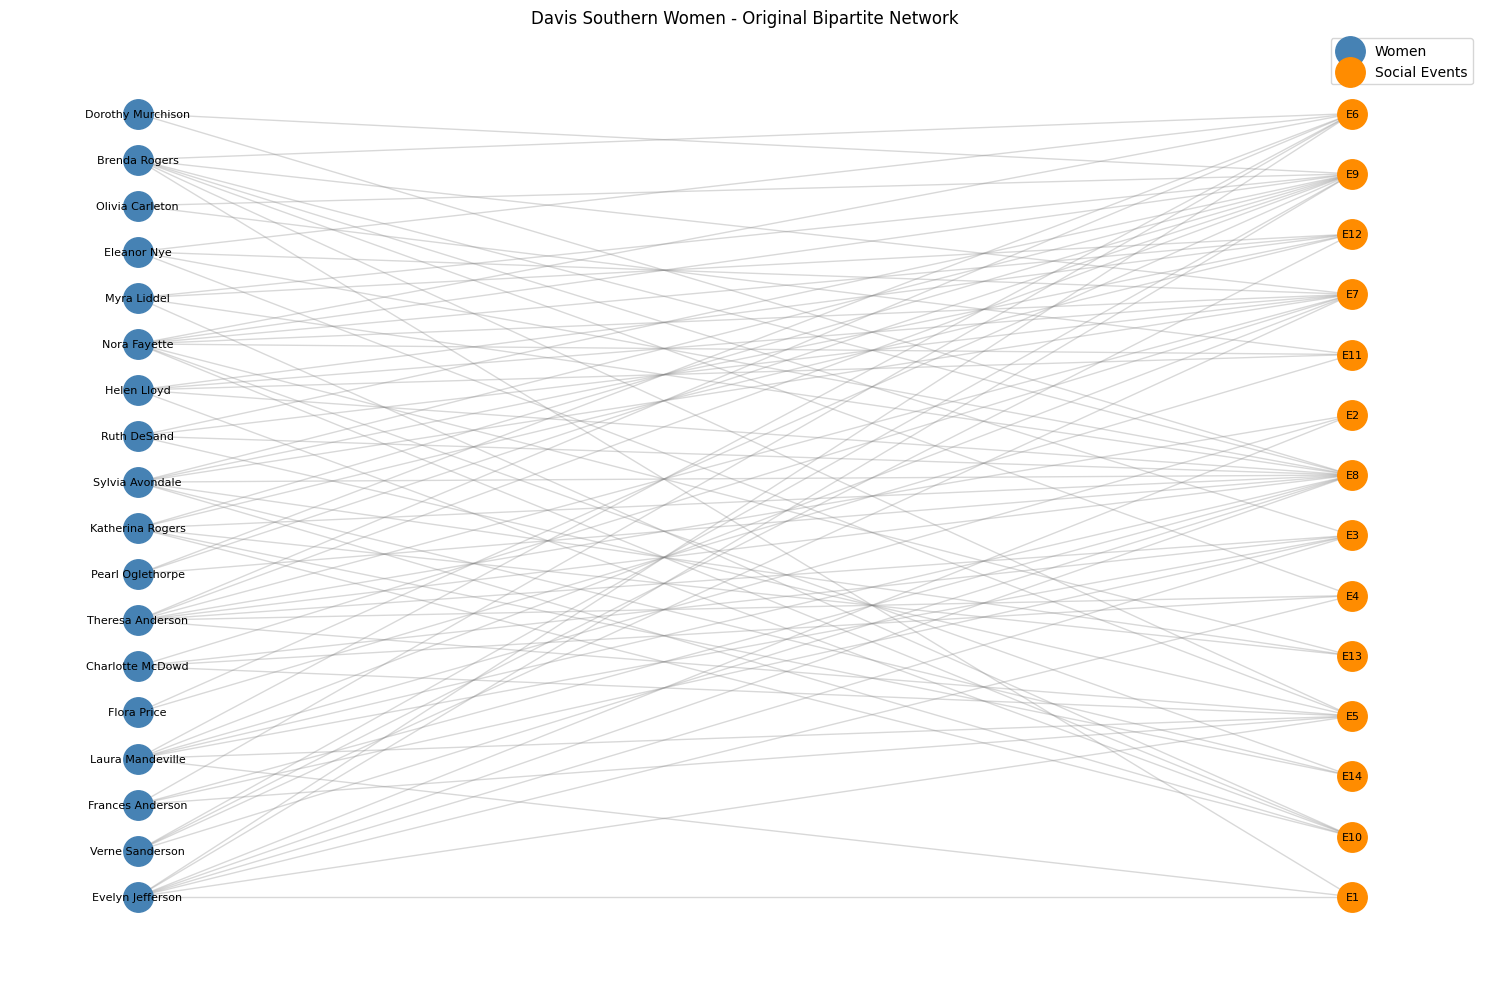

In [1]:
# 2. VISUALIZE ORIGINAL BIPARTITE NETWORK
# ==================================================

pos = nx.bipartite_layout(G, women)

plt.figure(figsize=(15, 10))

nx.draw_networkx_nodes(
    G, pos,
    nodelist=women,
    node_color="steelblue",
    node_size=450,
    label="Women"
)

nx.draw_networkx_nodes(
    G, pos,
    nodelist=events,
    node_color="darkorange",
    node_size=450,
    label="Social Events"
)

nx.draw_networkx_edges(
    G, pos,
    alpha=0.3,
    edge_color="gray"
)

nx.draw_networkx_labels(
    G, pos,
    font_size=8
)

plt.title("Davis Southern Women - Original Bipartite Network")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()


# ==================================================


The original graph correctly separates women and events and displays their attendance links. It is useful for understanding the data structure, although the crossing edges make it difficult to identify specific social groups directly. This motivates examining the two projections separately.

## 3. Projecting the Network onto Women

The original network does not directly connect women to one another. To study their relationships, I create a **weighted projection**: two women are linked when they attended at least one of the same events, and the edge weight is the number of events they shared. This provides a way to compare patterns of participation rather than assuming that co-attendance proves friendship.

In [1]:
# 3. CREATE WOMEN'S NETWORK PROJECTION
# ==================================================

# Two women are connected if they attended
# at least one of the same events.
# Weight = number of shared events.

W = bipartite.weighted_projected_graph(G, women)

print("\nWOMEN'S PROJECTED NETWORK")
print("--------------------------------")
print("Nodes:", W.number_of_nodes())
print("Edges:", W.number_of_edges())


# ==================================================



WOMEN'S PROJECTED NETWORK
--------------------------------
Nodes: 18
Edges: 139

WOMEN'S NETWORK ANALYSIS
--------------------------------


## 4. Women's Attendance and Centrality

I compare several measures because they answer different questions. **Events attended** measures participation; **shared-event partners** counts how many other women a person overlaps with at least once; **degree centrality** scales that count by the 17 possible partners; and **weighted connections** sums the numbers of shared events across all partners. The weighted measure helps distinguish frequent shared participation from a single shared appearance.

In [1]:
# 4. ANALYZE RELATIONSHIPS BETWEEN WOMEN
# ==================================================

women_results = pd.DataFrame({
    "Woman": women,
    "Events_Attended": [G.degree(w) for w in women],
    "Shared_Event_Partners": [W.degree(w) for w in women],
    "Degree_Centrality": [
        nx.degree_centrality(W)[w] for w in women
    ],
    "Weighted_Connections": [
        W.degree(w, weight="weight") for w in women
    ]
})

women_results = women_results.sort_values(
    "Weighted_Connections",
    ascending=False
)

print("\nWOMEN'S NETWORK ANALYSIS")
print("--------------------------------")
display(women_results.round(3))


# ==================================================


,Woman,Events_Attended,Shared_Event_Partners,Degree_Centrality,Weighted_Connections
2,Theresa Anderson,8,17,1.000,57
0,Evelyn Jefferson,8,17,1.000,50
3,Brenda Rogers,7,15,0.882,46
12,Sylvia Avondale,7,17,1.000,46
1,Laura Mandeville,7,15,0.882,45
13,Nora Fayette,8,17,1.000,43
8,Ruth DeSand,4,17,1.000,40
9,Verne Sanderson,4,17,1.000,38
11,Katherina Rogers,6,16,0.941,37
6,Eleanor Nye,4,15,0.882,36


**Interpretation.** The women's projected network contains 18 nodes and 139 edges, so most pairs of women share at least one event. Theresa Anderson has the highest weighted-connections total (57), followed by Evelyn Jefferson (50). Both attended eight events and each overlaps with all 17 other women. This suggests broad participation, but the degree-centrality scores alone cannot tell us how frequently any particular pair met.

## 5. Strongest Shared-Attendance Relationships

I rank pairs of women by their number of shared events. This is useful because a high degree-centrality score does not necessarily mean that any individual relationship is particularly strong: someone can overlap once with many people.

In [1]:
# 5. STRONGEST RELATIONSHIPS BETWEEN WOMEN
# ==================================================

women_pairs = pd.DataFrame(
    [
        {
            "Woman_1": u,
            "Woman_2": v,
            "Shared_Events": data["weight"]
        }
        for u, v, data in W.edges(data=True)
    ]
)

women_pairs = women_pairs.sort_values(
    "Shared_Events",
    ascending=False
)

print("\nTOP 10 WOMEN PAIRS BY SHARED EVENTS")
print("--------------------------------")
display(women_pairs.head(10))


# ==================================================



TOP 10 WOMEN PAIRS BY SHARED EVENTS
--------------------------------


,Woman_1,Woman_2,Shared_Events
9,Evelyn Jefferson,Theresa Anderson,7
126,Sylvia Avondale,Nora Fayette,6
24,Laura Mandeville,Theresa Anderson,6
15,Evelyn Jefferson,Brenda Rogers,6
29,Laura Mandeville,Brenda Rogers,6
1,Evelyn Jefferson,Laura Mandeville,6
44,Theresa Anderson,Brenda Rogers,6
118,Katherina Rogers,Sylvia Avondale,6
121,Katherina Rogers,Nora Fayette,5
38,Theresa Anderson,Charlotte McDowd,4


**Interpretation.** Evelyn Jefferson and Theresa Anderson shared seven events, the largest overlap in the dataset. Sylvia Avondale and Nora Fayette shared six. These repeated co-attendances are stronger evidence of common social participation than a single shared event, although they still do not establish personal friendship.

## 6. Visualizing Women's Shared Attendance

In the projected network, node size reflects the number of events attended, while edge thickness reflects the number of shared events. I use a spring layout to make the dense network easier to examine, not to measure literal social distance.

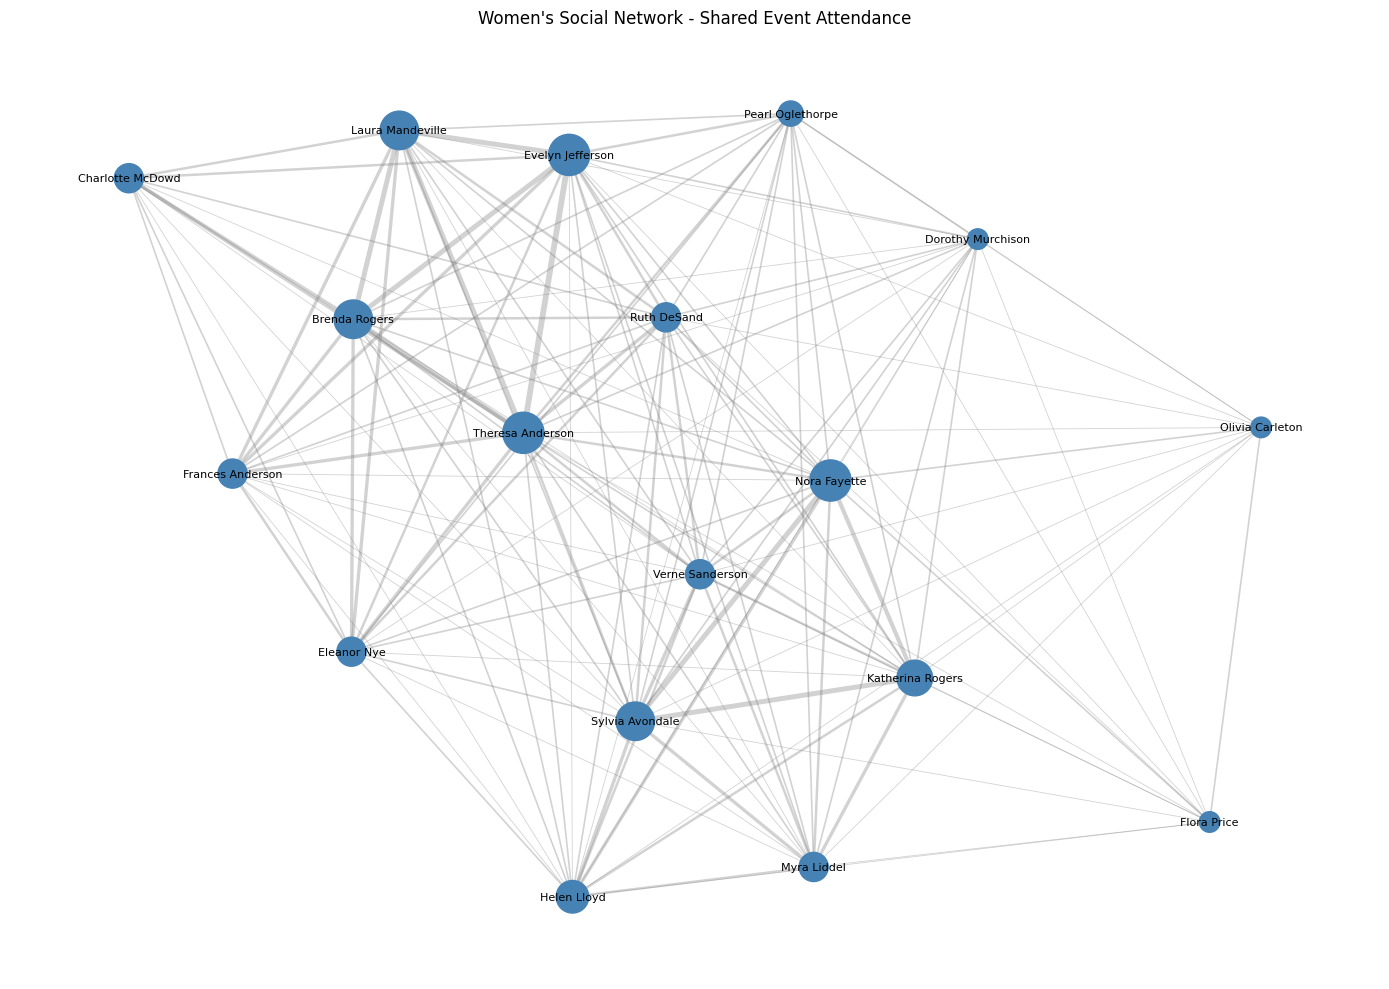

In [1]:
# 6. VISUALIZE WOMEN'S NETWORK
# ==================================================

pos_w = nx.spring_layout(W, seed=42, weight="weight")

plt.figure(figsize=(14, 10))

nx.draw_networkx_edges(
    W, pos_w,
    width=[W[u][v]["weight"] * 0.6 for u, v in W.edges()],
    alpha=0.35,
    edge_color="gray"
)

nx.draw_networkx_nodes(
    W, pos_w,
    node_color="steelblue",
    node_size=[G.degree(w) * 110 for w in W.nodes()]
)

nx.draw_networkx_labels(
    W, pos_w,
    font_size=8
)

plt.title("Women's Social Network - Shared Event Attendance")
plt.axis("off")
plt.tight_layout()
plt.show()


# ==================================================


**Interpretation.** The visualization shows a densely interconnected group rather than isolated individuals. Theresa Anderson and Evelyn Jefferson appear prominent, consistent with the tables. Some thicker edges indicate repeated shared attendance. Apparent clusters are suggestive, but I would not treat their positions in this layout as proof of separate communities.

## 7. Projecting the Network onto Events

I repeat the projection in the opposite direction. Two events are connected when at least one woman attended both, and the edge weight counts the shared attendees. This helps identify gatherings with similar audiences and events that connect different attendance patterns.

In [1]:
# 7. CREATE EVENTS NETWORK PROJECTION
# ==================================================

# Two events are connected if they share
# at least one attendee.
# Weight = number of shared women.

E = bipartite.weighted_projected_graph(G, events)

print("\nEVENTS PROJECTED NETWORK")
print("--------------------------------")
print("Nodes:", E.number_of_nodes())
print("Edges:", E.number_of_edges())


# ==================================================



EVENTS PROJECTED NETWORK
--------------------------------
Nodes: 14
Edges: 66

EVENT ATTENDANCE AND CENTRALITY
--------------------------------


## 8. Event Attendance and Centrality

For events, **attendance** is the number of women present, **related events** counts other gatherings with at least one common attendee, and **weighted connections** adds up shared-attendee counts across event pairs. Comparing these measures helps distinguish a popular event from one whose attendees also participate broadly elsewhere.

In [1]:
# 8. ANALYZE RELATIONSHIPS BETWEEN EVENTS
# ==================================================

event_centrality = nx.degree_centrality(E)

events_results = pd.DataFrame({
    "Event": events,
    "Attendance": [G.degree(e) for e in events],
    "Related_Events": [E.degree(e) for e in events],
    "Degree_Centrality": [
        event_centrality[e] for e in events
    ],
    "Weighted_Connections": [
        E.degree(e, weight="weight") for e in events
    ]
})

events_results = events_results.sort_values(
    "Attendance",
    ascending=False
)

print("\nEVENT ATTENDANCE AND CENTRALITY")
print("--------------------------------")
display(events_results.round(3))


# ==================================================


,Event,Attendance,Related_Events,Degree_Centrality,Weighted_Connections
7,E8,14,13,1.000,59
8,E9,12,13,1.000,46
6,E7,10,13,1.000,48
4,E5,8,8,0.615,38
5,E6,8,13,1.000,41
2,E3,6,8,0.615,32
11,E12,6,8,0.615,28
9,E10,5,8,0.615,25
3,E4,4,8,0.615,23
10,E11,4,8,0.615,13


**Interpretation.** E8 was the most attended event (14 women), followed by E9 (12) and E7 (10). E8 also had the highest weighted-connections total (59). E7, E8, and E9 were each connected to all 13 other events through shared attendees. Together, these measures suggest that these gatherings were important points of overlap in the observed attendance network.

## 9. Events with the Most Overlapping Attendees

I rank pairs of events by shared attendees to identify the strongest overlaps directly. These counts offer more specific evidence than the network layout alone.

In [1]:
# 9. STRONGEST RELATIONSHIPS BETWEEN EVENTS
# ==================================================

event_pairs = pd.DataFrame(
    [
        {
            "Event_1": u,
            "Event_2": v,
            "Shared_Attendees": data["weight"]
        }
        for u, v, data in E.edges(data=True)
    ]
)

event_pairs = event_pairs.sort_values(
    "Shared_Attendees",
    ascending=False
)

print("\nTOP 10 EVENT PAIRS BY SHARED ATTENDEES")
print("--------------------------------")
display(event_pairs.head(10))


# ==================================================



TOP 10 EVENT PAIRS BY SHARED ATTENDEES
--------------------------------


,Event_1,Event_2,Shared_Attendees
49,E8,E9,9
41,E7,E8,8
33,E6,E8,7
26,E5,E8,7
27,E5,E7,6
15,E3,E5,6
29,E5,E6,6
50,E8,E12,5
20,E3,E6,5
44,E7,E9,5


**Interpretation.** E8 and E9 shared nine attendees, the strongest event-pair overlap. E7 and E8 shared eight, while E6 and E8 shared seven. This shows that E8 drew participants who also attended several other gatherings; however, high overlap partly reflects E8's large overall attendance.

## 10. Visualizing Relationships Between Events

Node size represents attendance, and thicker edges represent more shared attendees. I use this graph to look for clusters of gatherings and possible links between them. Node positions are produced by the layout algorithm, so interpretation should focus on connections and weights rather than exact distances.

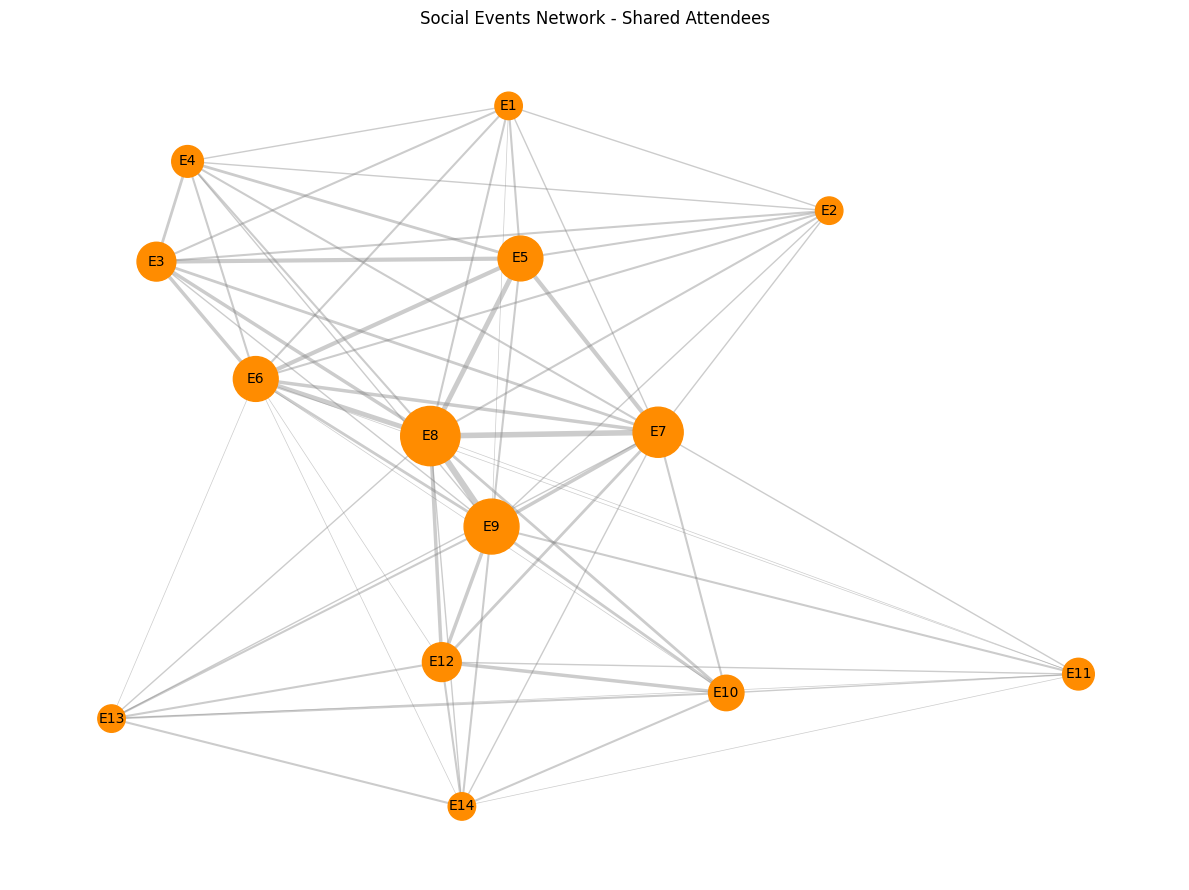

In [1]:
# 10. VISUALIZE EVENTS NETWORK
# ==================================================

pos_e = nx.spring_layout(E, seed=42, weight="weight")

plt.figure(figsize=(12, 9))

nx.draw_networkx_edges(
    E, pos_e,
    width=[E[u][v]["weight"] * 0.5 for u, v in E.edges()],
    alpha=0.4,
    edge_color="gray"
)

nx.draw_networkx_nodes(
    E, pos_e,
    node_color="darkorange",
    node_size=[G.degree(e) * 130 for e in E.nodes()]
)

nx.draw_networkx_labels(
    E, pos_e,
    font_size=10
)

plt.title("Social Events Network - Shared Attendees")
plt.axis("off")
plt.tight_layout()
plt.show()


# ==================================================


**Interpretation.** E8 stands out as a large, centrally positioned event with several thick links. The graph also suggests two overlapping sets of gatherings, with E7–E9 connecting attendance patterns across them. The strongest evidence for this interpretation is the shared-attendee counts and attendance matrix, rather than the visual positions alone.

## 11. Attendance Matrix

The attendance matrix provides a direct check on the network findings: a value of 1 means a woman attended that event, and 0 means she did not. Viewing all attendance patterns together helps reveal whether some women tend to attend earlier-numbered or later-numbered events and where those patterns overlap. Event numbers are identifiers; they should not automatically be treated as a timeline.

In [1]:
# 11. ATTENDANCE MATRIX
# ==================================================

attendance_matrix = pd.DataFrame(
    bipartite.biadjacency_matrix(
        G,
        row_order=women,
        column_order=events
    ).toarray(),
    index=women,
    columns=events
)

print("\nWOMEN-EVENT ATTENDANCE MATRIX")
print("--------------------------------")
display(attendance_matrix)


# ==================================================



WOMEN-EVENT ATTENDANCE MATRIX
--------------------------------


,E1,E2,E3,E4,E5,E6,E7,E8,E9,E10,E11,E12,E13,E14
Evelyn Jefferson,1,1,1,1,1,1,0,1,1,0,0,0,0,0
Laura Mandeville,1,1,1,0,1,1,1,1,0,0,0,0,0,0
Theresa Anderson,0,1,1,1,1,1,1,1,1,0,0,0,0,0
Brenda Rogers,1,0,1,1,1,1,1,1,0,0,0,0,0,0
Charlotte McDowd,0,0,1,1,1,0,1,0,0,0,0,0,0,0
Frances Anderson,0,0,1,0,1,1,0,1,0,0,0,0,0,0
Eleanor Nye,0,0,0,0,1,1,1,1,0,0,0,0,0,0
Pearl Oglethorpe,0,0,0,0,0,1,0,1,1,0,0,0,0,0
Ruth DeSand,0,0,0,0,1,0,1,1,1,0,0,0,0,0
Verne Sanderson,0,0,0,0,0,0,1,1,1,0,0,1,0,0


**Interpretation.** Several women, including Evelyn Jefferson and Brenda Rogers, participated primarily in E1–E8, while Katherina Rogers, Sylvia Avondale, and Nora Fayette participated more in E9–E14. The patterns overlap around E7–E9. This is consistent with two partially overlapping social circles, but it is an exploratory interpretation rather than a formal community-detection result.

## 12. Summary of Key Results

I collect the most active women, strongest shared-attendance pairs, most popular events, and most overlapping event pairs in one place to support the final interpretation.

In [1]:
# 12. SUMMARY
# ==================================================

print("\nFINAL SUMMARY")
print("--------------------------------")

print("\nMost active women by event attendance:")
display(
    women_results.sort_values(
        "Events_Attended", ascending=False
    )[["Woman", "Events_Attended"]].head(5)
)

print("\nWomen with strongest shared-event connections:")
display(women_pairs.head(5))

print("\nMost attended events:")
display(
    events_results[["Event", "Attendance"]].head(5)
)

print("\nEvents with the most shared attendees:")
display(event_pairs.head(5))

print("\nAnalysis complete.")


FINAL SUMMARY
--------------------------------

Most active women by event attendance:


,Woman,Events_Attended
2,Theresa Anderson,8
13,Nora Fayette,8
0,Evelyn Jefferson,8
3,Brenda Rogers,7
12,Sylvia Avondale,7



Women with strongest shared-event connections:


,Woman_1,Woman_2,Shared_Events
9,Evelyn Jefferson,Theresa Anderson,7
126,Sylvia Avondale,Nora Fayette,6
24,Laura Mandeville,Theresa Anderson,6
15,Evelyn Jefferson,Brenda Rogers,6
29,Laura Mandeville,Brenda Rogers,6



Most attended events:


,Event,Attendance
7,E8,14
8,E9,12
6,E7,10
4,E5,8
5,E6,8



Events with the most shared attendees:


,Event_1,Event_2,Shared_Attendees
49,E8,E9,9
41,E7,E8,8
33,E6,E8,7
26,E5,E8,7
27,E5,E7,6



Analysis complete.


## Discussion

The two projections answer different aspects of the assignment. The women's network shows that Theresa Anderson and Evelyn Jefferson had broad shared-attendance connections, and that certain pairs repeatedly attended the same gatherings. The events network identifies E8 as especially prominent in both attendance and overlap with other events.

The attendance matrix suggests that participation was not completely uniform. Some women appeared more frequently at one set of events, others at another set, and several events brought those patterns together. This is a useful example of why network analysis adds information beyond simple attendance totals.

## Limitations

The network records event attendance, not direct evidence of friendships, communication, or the reasons for attending. Shared attendance also does not guarantee that two people interacted. In a weighted projection, large events can create many connections at once, so high connectivity can partly reflect event size. Finally, the visual clusters are exploratory and have not been validated with a formal community-detection method.

## Conclusion

The Davis Southern Women network shows how a small bipartite dataset can reveal meaningful patterns of shared social participation. Theresa Anderson and Evelyn Jefferson stood out in the women's projection, while E8, E9, and E7 were prominent in the events analysis. The results suggest overlapping attendance groups linked through several gatherings. Using weighted projections, centrality, visualizations, and the attendance matrix made it possible to examine both relationships among women and relationships among events without claiming that co-attendance proves friendship.